# Hit callers on cells and on guide profiles

{func}`~mantispy.tl.hit_calling` offers four statistics, and a screen can be tested at two stages: on the single
cells, or on one median profile per guide. This page runs every method that applies at each stage on the same screen,
and compares the calls with a set of genes whose answer is known.

The screen is {func}`~mantispy.ds.scallops_arv471`, an optical pooled CRISPR screen in MCF7 cells treated with the
estrogen-receptor degrader ARV-471. The drug needs the CRL4-CRBN ligase to degrade the receptor, so knocking out
`CRBN`, `DDB1`, `CUL4A`, `CUL4B` or the receptor itself (`ESR1`) changes the phenotype: these five are the known
positives. Twelve olfactory-receptor genes are not expressed in these cells and are the known negatives. The other
genes of the library have no known answer, so they are counted but not scored.
[Hit callers on well profiles](../compounds/hit_calling_methods.ipynb) compares the default with `"mp_value"` on
compound screens.

In [1]:
import time

import pandas as pd

import mantispy as mt

POSITIVES = ["CRBN", "DDB1", "CUL4A", "CUL4B", "ESR1"]

cells = mt.ds.scallops_arv471()
mt.pp.normalize(cells, by="Metadata_Plate", reference="negcon")
genes = cells.obs["Metadata_Gene"].astype(str)
NEGATIVES = sorted(gene for gene in genes.unique() if gene.startswith("OR"))
# Two million cells is more than the comparison needs; keep 200 per guide.
cells = mt.pp.downsample(cells, n_per_group=200, by="Metadata_sgRNA")
cells

AnnData object with n_obs × n_vars = 135549 × 9
    obs: 'Metadata_Gene', 'Metadata_sgRNA', 'Metadata_Control_Type', 'Metadata_Control', 'Metadata_Perturbation', 'Metadata_Plate', 'Metadata_Well', 'Metadata_Row', 'Metadata_Col', 'Metadata_ImageID', 'Metadata_ObjectType', 'Metadata_ObjectNumber', 'Metadata_Perturbation_Type'
    var: 'object', 'feature_group', 'feature', 'channel', 'scale', 'angle', 'gray_levels', 'radial_bin', 'params', 'is_feature', 'feature_kind', 'degenerate_scale'
    uns: 'mantispy'
    layers: None (.X)

In [2]:
def score(calls):
    """Confusion counts of each method's calls against the known positives and negatives."""
    rows = {}
    for method, called in calls.items():
        rows[method] = {
            "positives called": int(called.reindex(POSITIVES).sum()),
            "positives missed": int((~called.reindex(POSITIVES)).sum()),
            "negatives called": int(called.reindex(NEGATIVES).sum()),
            "negatives not called": int((~called.reindex(NEGATIVES)).sum()),
            "other genes called": int(called.drop(POSITIVES + NEGATIVES + ["nontargeting"], errors="ignore").sum()),
        }
    return pd.DataFrame(rows).T


def agreement(calls):
    """Share of genes on which two methods make the same call."""
    frame = pd.DataFrame(calls)
    return pd.DataFrame({a: {b: (frame[a] == frame[b]).mean() for b in frame} for a in frame}).round(2)


def call(adata, methods):
    """Run each method on the genes and return its calls at q < 0.05 and its runtime."""
    calls, seconds = {}, {}
    for name, keywords in methods.items():
        start = time.perf_counter()
        mt.tl.hit_calling(adata, groupby="Metadata_Gene", n_permutations=1000, key_added=name, **keywords)
        seconds[name] = round(time.perf_counter() - start, 1)
        calls[name] = adata.uns["mantispy"][name].set_index("group")["qvalue"] < 0.05
    return calls, pd.Series(seconds, name="seconds")

## Single cells

Every well of a pooled screen holds every guide, so the unit the null draws whole is the guide (`replicate=`).
The four statistics ask different questions of a gene's cells:

- `"mahalanobis"`: how far the gene's typical cell sits from the non-targeting cells, in the controls' covariance.
- `"ks"`: whether the distribution of the cells' distances differs, which also catches a subpopulation that moved.
- `"hellinger"`: how little a Gaussian fitted to the gene's cells overlaps one fitted to the controls, so a change in
  spread or shape counts as well as a shift. It follows the robust morphological perturbation value of BioProfiling.jl
  (Vulliard et al., *Bioinformatics* 2022, [doi:10.1093/bioinformatics/btab853](https://doi.org/10.1093/bioinformatics/btab853)),
  which builds on the multidimensional perturbation value (Hutz et al., *J Biomol Screen* 2013,
  [doi:10.1177/1087057112469257](https://doi.org/10.1177/1087057112469257)).
  `covariance="robust"` gives BioProfiling.jl's robust variant; it refits the fits on every permutation and takes far
  longer, so it is left out here.

  The statistic is one minus the overlap of the two Gaussians. That overlap is a term for how much the two
  spreads differ, times exp(-Δμᵀ S⁻¹ Δμ / 8), where Δμ is the difference between the means and S is the average of
  the two covariances. The second factor is the squared Mahalanobis distance in the pooled covariance, the form the
  multidimensional perturbation value uses, so a pure shift in the mean still counts, and a change in spread adds to it.
- `"mp_value"`: that squared Mahalanobis distance alone, between the gene's centroid and the controls', in the
  average of the two covariances. This is the multidimensional perturbation value itself. Only the average has to be
  positive definite, so a gene needs two rows rather than twice as many rows as features.

In [3]:
cell_calls, cell_seconds = call(
    cells,
    {
        "mahalanobis": {"replicate": "Metadata_sgRNA"},
        "ks": {"method": "ks", "replicate": "Metadata_sgRNA"},
        "hellinger": {"method": "hellinger", "replicate": "Metadata_sgRNA"},
        "mp_value": {"method": "mp_value", "replicate": "Metadata_sgRNA"},
    },
)
score(cell_calls).assign(seconds=cell_seconds)

,positives called,positives missed,negatives called,negatives not called,other genes called,seconds
mahalanobis,2,3,1,11,46,8.4
ks,2,3,1,11,55,25.0
hellinger,2,3,0,12,5,79.1
mp_value,4,1,9,3,110,3.5


In [4]:
agreement(cell_calls)

,mahalanobis,ks,hellinger,mp_value
mahalanobis,1.00,0.91,0.74,0.53
ks,0.91,1.00,0.68,0.58
hellinger,0.74,0.68,1.00,0.27
mp_value,0.53,0.58,0.27,1.00


`"mahalanobis"`, `"ks"` and `"hellinger"` each call two of the five positives and miss the other three.
`"mahalanobis"` and `"ks"` each call one of the twelve negatives, and `"hellinger"` calls none. `"mp_value"` calls four
of the five positives, but also nine of the twelve negatives. The negatives are guides that cut genes the cells do not
express, so a method that calls them is reading a difference from the non-targeting guides that has nothing to do with
the target. `"mp_value"` tests the centre of all of a gene's cells directly, which makes it the most likely of the
four to pick up a small shift that every cutting guide shares (see the end of this page).

The methods differ most among the genes without a known answer: `"hellinger"` calls 5 of them, `"mahalanobis"` 46,
`"ks"` 55 and `"mp_value"` 110. The truth set cannot say which of those calls are right, but it shows that
`"hellinger"` returns the shortest list at the same recall on the known positives. It is also the slowest of the four,
and `"mp_value"` the fastest. `"mahalanobis"` and `"ks"` agree on 91% of the genes, and `"hellinger"` agrees with them
on 74% and 68%. `"mp_value"` agrees with them on 53% and 58%, and with `"hellinger"` on 27%.

### Calibrating hit calls with pseudo-genes

A per-feature caller such as {func}`~mantispy.tl.bootstrap_features` runs one test per gene and feature, and whether
its p-values hold on a given screen is something to measure. {func}`~mantispy.pp.pseudogenes` cuts the non-targeting
guides into groups the size of a real gene, and the bootstrap tests each group against every other control guide. A
pseudo-gene has no phenotype, so every call it gets is a false call.

The screen here is {func}`~mantispy.ds.aconcagua_cells`, single HeLa cells of eight genes and their non-targeting
controls. To keep the run short, only the intensity features are tested.

In [5]:
acon = mt.ds.aconcagua_cells()
acon = acon[:, acon.var_names.str.contains("_Intensity_")].copy()
mt.pp.pseudogenes(acon, replicate="Metadata_Guide")
mt.tl.bootstrap_features(acon, groupby="Metadata_Gene_pseudo", replicate="Metadata_Guide")
table = acon.uns["mantispy"]["bootstrap"]
table.groupby("is_pseudogene").agg(groups=("group", "nunique"), tests=("pvalue", "count"))

,groups,tests
is_pseudogene,,
False,8,2112
True,62,16368


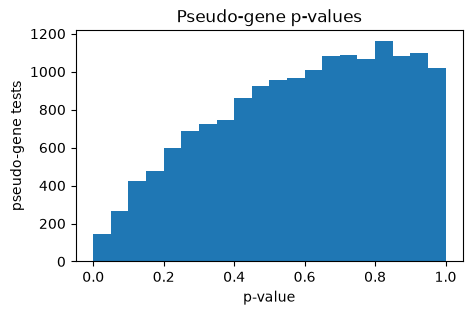

In [6]:
import matplotlib.pyplot as plt

pseudo = table[table["is_pseudogene"]].dropna(subset=["pvalue"])
fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(pseudo["pvalue"], bins=20, range=(0, 1))
ax.set_xlabel("p-value")
ax.set_ylabel("pseudo-gene tests")
ax.set_title("Pseudo-gene p-values")
plt.show()

In [7]:
from scipy.stats import binomtest

real = table[~table["is_pseudogene"]]
cutoff = real.loc[real["qvalue"] < 0.05, "pvalue"].max()
called = pseudo["pvalue"] <= cutoff
interval = binomtest(int(called.sum()), len(called)).proportion_ci(0.95)
per_gene = called.groupby(pseudo["group"]).any()
pd.Series(
    {
        "real gene-feature pairs at q < 0.05": int((real["qvalue"] < 0.05).sum()),
        "p-value cutoff of those calls": round(cutoff, 4),
        "pseudo-gene tests called": f"{int(called.sum())} of {len(called)}",
        "per-test rate": f"{called.mean():.2%} (95% interval {interval.low:.2%} to {interval.high:.2%})",
        "pseudo-genes with a feature called": f"{int(per_gene.sum())} of {per_gene.size}",
        "per-gene rate": f"{per_gene.mean():.1%}",
    },
    name="value",
).to_frame()

,value
real gene-feature pairs at q < 0.05,1123
p-value cutoff of those calls,0.0264
pseudo-gene tests called,45 of 16368
per-test rate,0.27% (95% interval 0.20% to 0.37%)
pseudo-genes with a feature called,21 of 62
per-gene rate,33.9%


A calibrated test gives uniform p-values to the pseudo-genes. Here the histogram rises from under 200 tests in the
lowest bin to over 1,000 above 0.6, so the pseudo-genes get fewer small p-values than that: the bootstrap is
conservative on this screen.

The real genes have 1123 of their 2112 gene-feature pairs at q < 0.05, and Benjamini-Hochberg reaches that by calling
every p-value up to 0.0264. At that cutoff 45 of the 16368 pseudo-gene tests are called, a per-test rate of 0.27% (95%
interval 0.20% to 0.37%), where a calibrated test would call about 2.64%. The interval treats the tests as independent,
and the features of one pseudo-gene are not, so the real uncertainty is wider. Still, 21 of the 62 pseudo-genes have at
least one of their 264 features called, a per-gene rate of 33.9%: a gene is tested on every feature, so rare false calls
per test add up per gene.

If the per-test rate came out above the cutoff, the test would call more null features than it claims; scope the null
with `control_scope` (for example `"within_group"` with `condition="Metadata_Plate"`), or tighten the threshold until
the pseudo-genes stop passing. A per-gene rate like this one says that a gene called on a single feature is weak
evidence; count the features each gene is called on and compare that with the pseudo-genes, as
{func}`~mantispy.tl.empirical_fdr` does when given the pseudo-gene labels as its controls.

## Guide profiles

The same normalized cells, collapsed to one median profile per guide with {func}`~mantispy.tl.aggregate`, so that the
two stages see the same measurements. A gene now has a handful of rows, its guides. `"hellinger"` needs a covariance
within each group, and a covariance in nine features needs at least twice as many rows as features on each side, so it
does not apply at this stage. `"mp_value"` needs only the average of the gene's and the controls' covariances to be
positive definite, so it runs here alongside the other two, and each guide profile is its own unit.

In [8]:
guides = mt.tl.aggregate(cells, by=("Metadata_Gene", "Metadata_sgRNA"), func="median")
guide_calls, guide_seconds = call(
    guides, {"mahalanobis": {}, "ks": {"method": "ks"}, "mp_value": {"method": "mp_value"}}
)
score(guide_calls).assign(seconds=guide_seconds)

WARNING  hit_calling: 157 group(s) left unscored (AMBRA1, AMD1, ARID1A, BARD1, BRCA1, ...)

,positives called,positives missed,negatives called,negatives not called,other genes called,seconds
mahalanobis,1,4,0,12,3,0.1
ks,2,3,0,12,11,0.1
mp_value,1,4,0,12,1,2.4


In [9]:
agreement(guide_calls)

,mahalanobis,ks,mp_value
mahalanobis,1.00,0.93,0.96
ks,0.93,1.00,0.92
mp_value,0.96,0.92,1.00


On guide profiles no method calls a negative. `"mahalanobis"` finds one positive and `"ks"` two, along with 3 and 11
other genes, and each runs in a fraction of a second because a gene now has four rows instead of eight hundred.
`"mp_value"` leaves 157 genes unscored, with a warning. A spot count's median is a whole number, and one of
them, `Nuclei_Spots_Count_ESR1`, takes the same value for every non-targeting guide, so the controls do not vary in it
and the averaged covariance is singular. It calls two genes, one of them a positive.

## Cells or profiles

On this screen `"mahalanobis"` recovers more positives from the cells than from the guide medians, and `"ks"` recovers
two at both stages. Guide profiles are quick to test and need nothing beyond {func}`~mantispy.tl.aggregate`.
Cells take longer, but they are the only stage where `"hellinger"` applies and where a change in the spread of a gene's
cells can show at all. `"mp_value"` finds the most positives on cells and calls most of the negatives with them, and on
guide medians of these counts it cannot score most genes. `"mahalanobis"` stays the default because on cells it finds
as many positives as `"ks"` or `"hellinger"` at a fraction of their runtime, with one negative where `"mp_value"` calls
nine.
`"hellinger"` is the choice when a shorter list, built on the shape of the cell cloud as well as its centre, matters
more than speed.

Every targeting guide cuts DNA and a non-targeting guide does not, so against non-targeting controls the cutting
response alone can make most knockouts look active, here and in `tl.map(mode="activity")`. Guides against genes the
cells do not express, such as the olfactory receptors above, cut without changing a target, so they separate a gene's
effect from cutting. {func}`~mantispy.io.unexpressed_genes` lists those genes for a cell line, and
{func}`~mantispy.tl.empirical_fdr` calibrates the calls against them.